# 02 · Thresholding: turn intensity into a mask

**Level:** beginner. **Time:** 45–60 minutes of learning; the default run is short and CPU-only.

**Prerequisites:** notebook 01, NumPy indexing, and the idea that an image is an array. You can run this notebook independently with **Restart Kernel → Run All**.

**You will:** construct a known answer; choose a threshold from a histogram; compare manual, Otsu, and local thresholding; diagnose illumination and polarity failures. All examples run offline.

**Learning habit:** predict the next plot before running each cell. Keep your predictions in a new Markdown cell. A synthetic mask is exact because we created it; it is not a human annotation of a real photograph.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


## 1. Build an image with a known foreground

Coordinates are `(row, column)`. Our objects are bright disks on a dark background. Gaussian noise creates overlap between foreground and background intensities. A Boolean mask means `True = foreground`; it is not an RGB visualization.


In [2]:
from skimage import filters, data, util

rng = np.random.default_rng(11)
rows, cols = np.mgrid[:128, :160]
truth = np.zeros((128, 160), dtype=bool)
for row, col, radius in [(34, 35, 18), (88, 49, 23), (63, 119, 21)]:
    truth |= (rows - row) ** 2 + (cols - col) ** 2 <= radius ** 2
image = np.clip(0.20 + 0.55 * truth + rng.normal(0, 0.09, truth.shape), 0, 1)
print("Image:", image.shape, image.dtype, "range:", image.min(), image.max())
print("Mask:", truth.shape, truth.dtype, "foreground fraction:", truth.mean().round(3))

def show_grid(images, titles, columns=3, cmap="gray", limits=None):
    """A small display helper; every array is still available for inspection."""
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.4 * rows), squeeze=False)
    for ax, image, title in zip(axes.flat, images, titles):
        kwargs = {} if limits is None else {"vmin": limits[0], "vmax": limits[1]}
        ax.imshow(image, cmap=cmap, **kwargs)
        ax.set_title(title)
        ax.axis("off")
    for ax in list(axes.flat)[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


Image: (128, 160) float64 range: 0.0 1.0
Mask: (128, 160) bool foreground fraction: 0.197


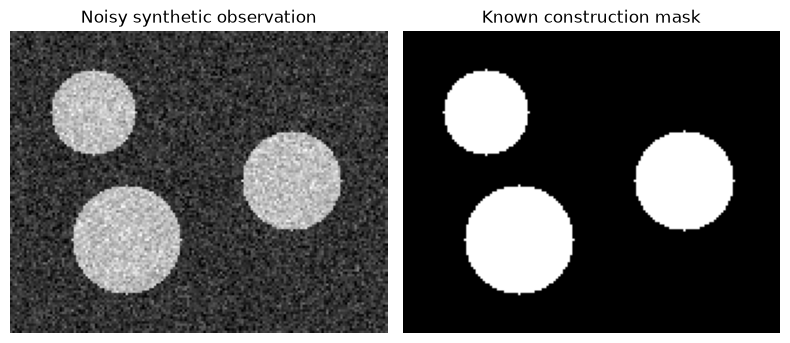

In [3]:
show_grid([image, truth], ["Noisy synthetic observation", "Known construction mask"], columns=2)


## 2. Use a histogram to make a decision

A global threshold makes the same decision at every location: `image > threshold`. On the left peak most pixels are background; on the right peak most are objects. A valley is a plausible dividing point. The histogram throws away spatial arrangement, so two very different scenes can have the same histogram.

**Predict:** what happens if you move the threshold from 0.45 to 0.70?


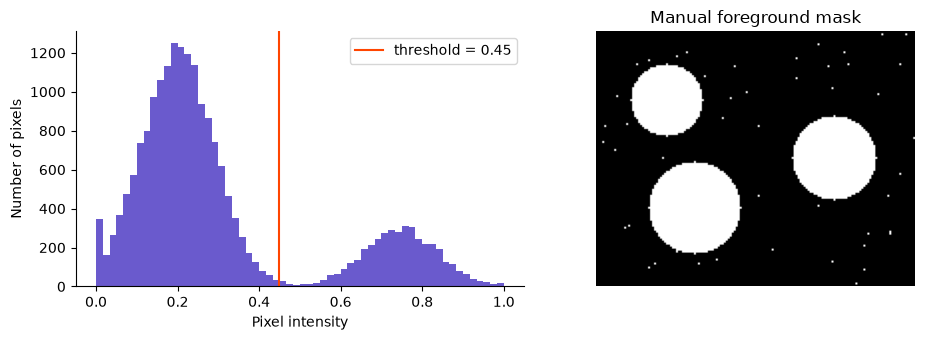

In [4]:
manual_threshold = 0.45
manual_mask = image > manual_threshold
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(image.ravel(), bins=60, range=(0, 1), color="slateblue")
axes[0].axvline(manual_threshold, color="orangered", label=f"threshold = {manual_threshold}")
axes[0].set(xlabel="Pixel intensity", ylabel="Number of pixels")
axes[0].legend()
axes[1].imshow(manual_mask, cmap="gray")
axes[1].set_title("Manual foreground mask")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 3. Measure overlap, not just appearance

For foreground masks, **intersection over union (IoU)** is `correct foreground / all pixels marked foreground by either mask`. False positives add unwanted pixels; false negatives miss true pixels. This introductory function scores two empty masks as 1 by explicit convention. Later evaluation lessons discuss dataset-level aggregation.

The known construction mask is used only for evaluation. We do not give it to Otsu.


Manual threshold 0.450: IoU = 0.988
Otsu threshold   0.471: IoU = 0.995


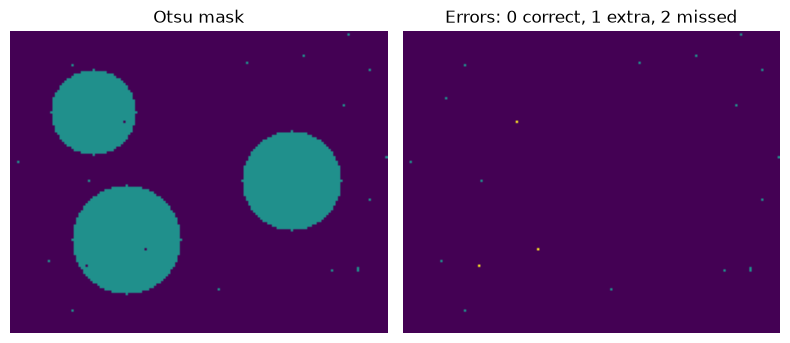

In [5]:
def binary_iou(target, prediction):
    target, prediction = np.asarray(target, bool), np.asarray(prediction, bool)
    if target.shape != prediction.shape:
        raise ValueError("Masks must have matching shapes")
    intersection = np.logical_and(target, prediction).sum()
    union = np.logical_or(target, prediction).sum()
    return float(intersection / union) if union else 1.0

otsu_threshold = filters.threshold_otsu(image)
otsu_mask = image > otsu_threshold
print(f"Manual threshold {manual_threshold:.3f}: IoU = {binary_iou(truth, manual_mask):.3f}")
print(f"Otsu threshold   {otsu_threshold:.3f}: IoU = {binary_iou(truth, otsu_mask):.3f}")
error_map = np.zeros(truth.shape, dtype=np.uint8)
error_map[otsu_mask & ~truth] = 1  # false positive
error_map[truth & ~otsu_mask] = 2  # false negative
show_grid([otsu_mask, error_map], ["Otsu mask", "Errors: 0 correct, 1 extra, 2 missed"],
          columns=2, cmap="viridis", limits=(0, 2))


Otsu chooses a threshold that separates intensity groups according to their variance. It does **not** know what a disk is. Here the scene was designed so brightness is informative.

## 4. Parameter experiment: sweep the threshold

The curve below is a teaching diagnostic, not an unbiased test result: it uses the known answer to inspect many settings. In a real project, tune on a validation set and report performance on a separate test set.


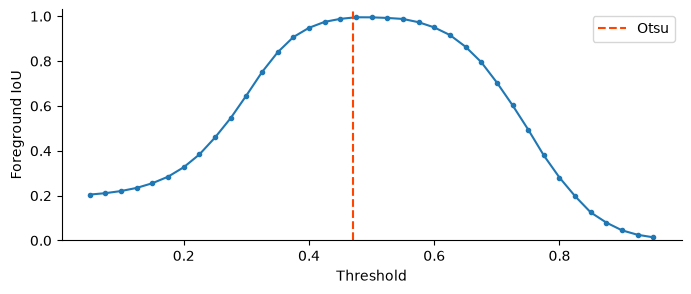

Broad good regions are more reassuring than a single fragile optimum.


In [6]:
thresholds = np.linspace(0.05, 0.95, 37)
scores = [binary_iou(truth, image > t) for t in thresholds]
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(thresholds, scores, "o-", markersize=3)
ax.axvline(otsu_threshold, color="orangered", linestyle="--", label="Otsu")
ax.set(xlabel="Threshold", ylabel="Foreground IoU", ylim=(0, 1.03))
ax.legend()
plt.show()
print("Broad good regions are more reassuring than a single fragile optimum.")


## 5. Create a failure: uneven illumination

Now the right side receives more light. Some background pixels become brighter than some object pixels. A single global threshold cannot perfectly separate the two groups. Small repeated objects make a useful local-threshold example because each neighborhood can contain both foreground and background.


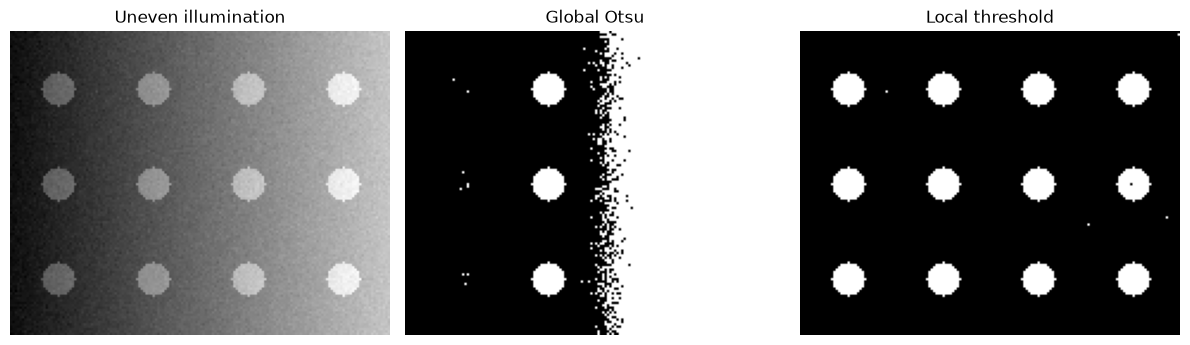

Global IoU: 0.129
Local IoU:  0.997


In [7]:
local_truth = np.zeros_like(truth)
for row in (24, 64, 104):
    for col in (20, 60, 100, 140):
        local_truth |= (rows - row) ** 2 + (cols - col) ** 2 <= 7 ** 2
illumination = 0.12 + 0.58 * cols / (cols.shape[1] - 1)
uneven = np.clip(illumination + 0.20 * local_truth + rng.normal(0, 0.015, truth.shape), 0, 1)
global_uneven = uneven > filters.threshold_otsu(uneven)
# threshold_local returns a threshold IMAGE, not a foreground mask.
local_threshold = filters.threshold_local(uneven, block_size=35, method="gaussian", offset=-0.05)
local_mask = uneven > local_threshold
show_grid([uneven, global_uneven, local_mask],
          ["Uneven illumination", "Global Otsu", "Local threshold"])
print(f"Global IoU: {binary_iou(local_truth, global_uneven):.3f}")
print(f"Local IoU:  {binary_iou(local_truth, local_mask):.3f}")


## 6. Interpret local parameters

`block_size` is an odd window width in pixels. Too small: the neighborhood follows the object itself. Too large: it stops adapting to illumination. With `threshold_local`, **the offset is subtracted** from the local statistic; a negative offset therefore raises the threshold and is stricter for bright foreground.

Compare these settings; explain one missed-object case and one background-noise case. A local method is not automatically better.


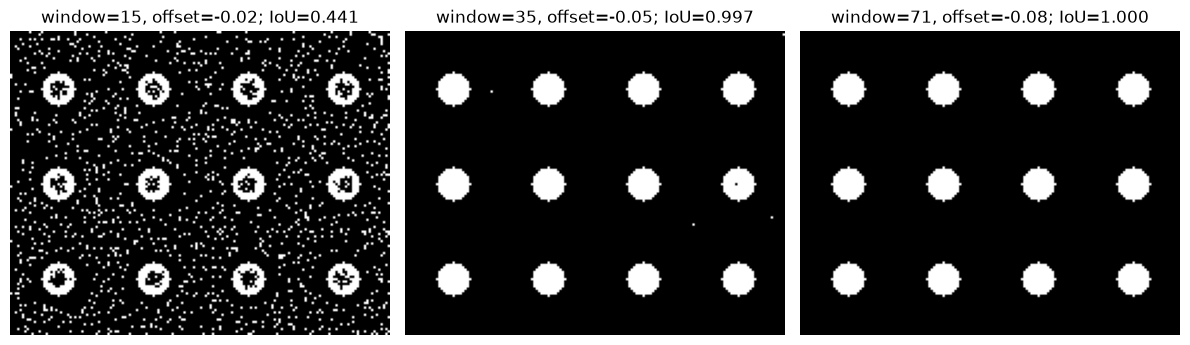

In [8]:
settings = [(15, -0.02), (35, -0.05), (71, -0.08)]
trial_masks, trial_titles = [], []
for block, offset in settings:
    threshold_map = filters.threshold_local(uneven, block_size=block, offset=offset)
    prediction = uneven > threshold_map
    trial_masks.append(prediction)
    trial_titles.append(f"window={block}, offset={offset}; IoU={binary_iou(local_truth, prediction):.3f}")
show_grid(trial_masks, trial_titles)


## 7. Transfer to a bundled real image

The scikit-image `coins` photograph is packaged with the library. We have **no reference mask** for this image in this lesson, so we can inspect results but cannot claim accuracy. The coin texture and uneven background violate our simple synthetic assumptions.


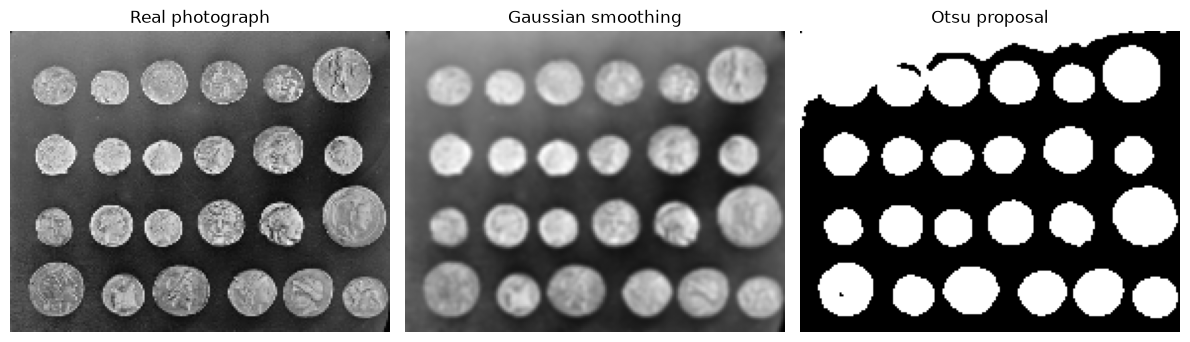

No real-image IoU is reported: we do not have an annotated reference mask.


In [9]:
coins = util.img_as_float(data.coins())[::2, ::2]
coins_smoothed = filters.gaussian(coins, sigma=1.0)
coins_mask = coins_smoothed > filters.threshold_otsu(coins_smoothed)
show_grid([coins, coins_smoothed, coins_mask], ["Real photograph", "Gaussian smoothing", "Otsu proposal"])
print("No real-image IoU is reported: we do not have an annotated reference mask.")


## 8. Exercises — try these in new cells

**A. Threshold polarity.** Segment dark objects in `1 - image`. Keep the original `truth`. Which comparison operator is required?

<details><summary>Worked solution A</summary>

```python
inverted = 1 - image
dark_mask = inverted < filters.threshold_otsu(inverted)
print(binary_iou(truth, dark_mask))
```
The foreground definition did not change; its brightness did. `>` would select the background.
</details>


**B. Noise robustness.** Generate three new versions with noise standard deviations 0.03, 0.12, and 0.25. Compare raw Otsu with Gaussian-smoothed Otsu. State one cost of smoothing.

<details><summary>Worked solution B</summary>

```python
experiment_rng = np.random.default_rng(20)
for noise in (0.03, 0.12, 0.25):
    noisy = np.clip(0.20 + 0.55 * truth + experiment_rng.normal(0, noise, truth.shape), 0, 1)
    smooth = filters.gaussian(noisy, sigma=1)
    raw = noisy > filters.threshold_otsu(noisy)
    cleaned = smooth > filters.threshold_otsu(smooth)
    print(noise, binary_iou(truth, raw), binary_iou(truth, cleaned))
```
Smoothing can suppress isolated errors but also moves edges and can erase tiny objects. Its benefit depends on object scale.
</details>


**C. Make local thresholding fail.** Replace the small disks in the uneven-light example with a filled rectangle of width 80. Keep `block_size=35`. Inspect its interior and explain the result.

<details><summary>Worked solution C</summary>

```python
wide_truth = np.zeros_like(truth)
wide_truth[30:98, 40:120] = True
wide_image = np.clip(illumination + 0.20 * wide_truth, 0, 1)
wide_threshold = filters.threshold_local(wide_image, 35, offset=-0.05)
wide_mask = wide_image > wide_threshold
show_grid([wide_image, wide_truth, wide_mask], ["Observation", "Truth", "Local result"])
```
A neighborhood wholly inside a broad object has no background reference. A larger window or illumination correction may help; the current local rule is poorly suited to this case.
</details>


## Common mistakes and debugging

- Mixing 0–255 integers with thresholds meant for 0–1 floats. Print the dtype and range first.
- Treating a threshold map as a binary mask. Compare the image to that map.
- Using `>` for every image. Decide whether foreground is brighter or darker.
- Comparing an RGB image with a 2D mask without understanding the channel axis.
- Selecting a parameter on the test image and calling the score independent evaluation.

## Completion checklist

- [ ] I can explain the two histogram peaks and threshold polarity.
- [ ] I can calculate the foreground IoU of two tiny hand-drawn masks.
- [ ] I can describe a scene where a global threshold fails.
- [ ] I completed A–C and recorded what changed.
- [ ] I understand why a pleasing real-image mask is not evidence of measured accuracy.

**Next:** notebook 03 repairs masks and turns foreground pixels into measurable objects.


## Official references

- [scikit-image thresholding guide](https://scikit-image.org/docs/stable/auto_examples/applications/plot_thresholding_guide.html)
- [Filter API: Otsu, local thresholds, Gaussian smoothing](https://scikit-image.org/docs/stable/api/skimage.filters.html)
- [Image dtype and intensity conventions](https://scikit-image.org/docs/stable/user_guide/data_types.html)

These are optional reading links; running this notebook does not access the internet.
